In [1]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [2]:
import os

# Cambia esta ruta por la ubicación real de tu carpeta del proyecto en Drive
project_path = '/content/drive/MyDrive/engineer-neural-networks-portfolio-project'
os.chdir(project_path)

# Verifica que estés en el directorio correcto listando los archivos (debe aparecer requirements.txt y la carpeta datasets)
!ls -l

total 2449
-rw------- 1 root root    2756 Nov  2 09:42 banking_classification_BERT.ipynb
-rw------- 1 root root 2498955 Oct 29 10:01 banking_classification_BERT_solution.ipynb
drwx------ 2 root root    4096 Oct 29 10:13 datasets
-rw------- 1 root root     575 Oct 29 10:01 requirements.txt


In [ ]:
!pip install -r requirements.txt

In [3]:
# Install PyTorch with CUDA support compatible with Python 3.13 first
!pip install torch torchvision torchaudio --index-url https://download.pytorch.org/whl/cu124

# Install the rest of the project dependencies from requirements.txt
!pip install -r requirements.txt

# Verify GPU availability
import torch
print("--- GPU Verification ---")
print("CUDA available:", torch.cuda.is_available())
if torch.cuda.is_available():
    print("Device name:", torch.cuda.get_device_name(0))

Looking in indexes: https://download.pytorch.org/whl/cu124
  Installing build dependencies ... done
  Getting requirements to build wheel ... done
  Preparing metadata (pyproject.toml) ... done
ERROR: Ignored the following versions that require a different python version: 1.10.0 Requires-Python >=3.8,<3.12; 1.10.0rc1 Requires-Python >=3.8,<3.12; 1.10.0rc2 Requires-Python >=3.8,<3.12; 1.10.1 Requires-Python >=3.8,<3.12; 1.11.0 Requires-Python >=3.9,<3.13; 1.11.0rc1 Requires-Python >=3.9,<3.13; 1.11.0rc2 Requires-Python >=3.9,<3.13; 1.11.1 Requires-Python >=3.9,<3.13; 1.11.2 Requires-Python >=3.9,<3.13; 1.11.3 Requires-Python >=3.9,<3.13; 1.21.2 Requires-Python >=3.7,<3.11; 1.21.3 Requires-Python >=3.7,<3.11; 1.21.4 Requires-Python >=3.7,<3.11; 1.21.5 Requires-Python >=3.7,<3.11; 1.21.6 Requires-Python >=3.7,<3.11; 1.26.0 Requires-Python >=3.9,<3.13; 1.26.1 Requires-Python >=3.9,<3.13; 1.6.2 Requires-Python >=3.7,<3.10; 1.6.3 Requires-Python >=3.7,<3.10; 1.7.0 Requires-Python >=3.7,<3.10

In [4]:
pwd

'/content/drive/MyDrive/engineer-neural-networks-portfolio-project'

In [5]:
ls

banking_classification_BERT.ipynb           datasets/
banking_classification_BERT_solution.ipynb  requirements.txt


**Load and Verify Data**


*Load the training and testing data to verify their existence and check for data quality issues, such as missing queries or intent labels.*

In [6]:
import pandas as pd

# Load the training and testing datasets
train_df = pd.read_csv('datasets/banking77_train.csv')
test_df = pd.read_csv('datasets/banking77_test.csv')

# Verify column names and basic schema info
print("=== Train Dataset Info ===")
print(train_df.info())
print("\n=== Test Dataset Info ===")
print(test_df.info())

# Check for missing values (null queries or labels)
print("\n=== Missing Values in Train Dataset ===")
print(train_df.isnull().sum())

print("\n=== Missing Values in Test Dataset ===")
print(test_df.isnull().sum())

# Display sample rows to verify text and category columns
print("\n=== Sample Rows (Train) ===")
display(train_df.head(3))

=== Train Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10003 entries, 0 to 10002
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      10003 non-null  object
 1   category  10003 non-null  object
dtypes: object(2)
memory usage: 156.4+ KB
None

=== Test Dataset Info ===
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3080 entries, 0 to 3079
Data columns (total 2 columns):
 #   Column    Non-Null Count  Dtype 
---  ------    --------------  ----- 
 0   text      3080 non-null   object
 1   category  3080 non-null   object
dtypes: object(2)
memory usage: 48.3+ KB
None

=== Missing Values in Train Dataset ===
text        0
category    0
dtype: int64

=== Missing Values in Test Dataset ===
text        0
category    0
dtype: int64

=== Sample Rows (Train) ===


,text,category
0,I am still waiting on my card?,card_arrival
1,What can I do if my card still hasn't arrived ...,card_arrival
2,I have been waiting over a week. Is the card s...,card_arrival


**Explore and Visualize the Data**

*Explore the data to become familiar with its characteristics by examining distributions, identifying initial insights, and strategizing cleaning and preprocessing steps for modeling. Consider exploring the data by creating visualizations, calculating descriptive statistics, and writing down initial findings.*

=== Dataset Overview ===
Total training samples: 10003
Total test samples: 3080
Number of unique intent categories: 77

=== Text Length Statistics (Train Set) ===
        char_length    word_count
count  10003.000000  10003.000000
mean      59.475057     11.949415
std       40.867716      7.891577
min       13.000000      2.000000
25%       36.000000      7.000000
50%       47.000000     10.000000
75%       64.000000     13.000000
max      433.000000     79.000000


/tmp/ipykernel_526/2388596054.py:34: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_categories.values, y=top_categories.index, ax=axes[1], palette='crest')


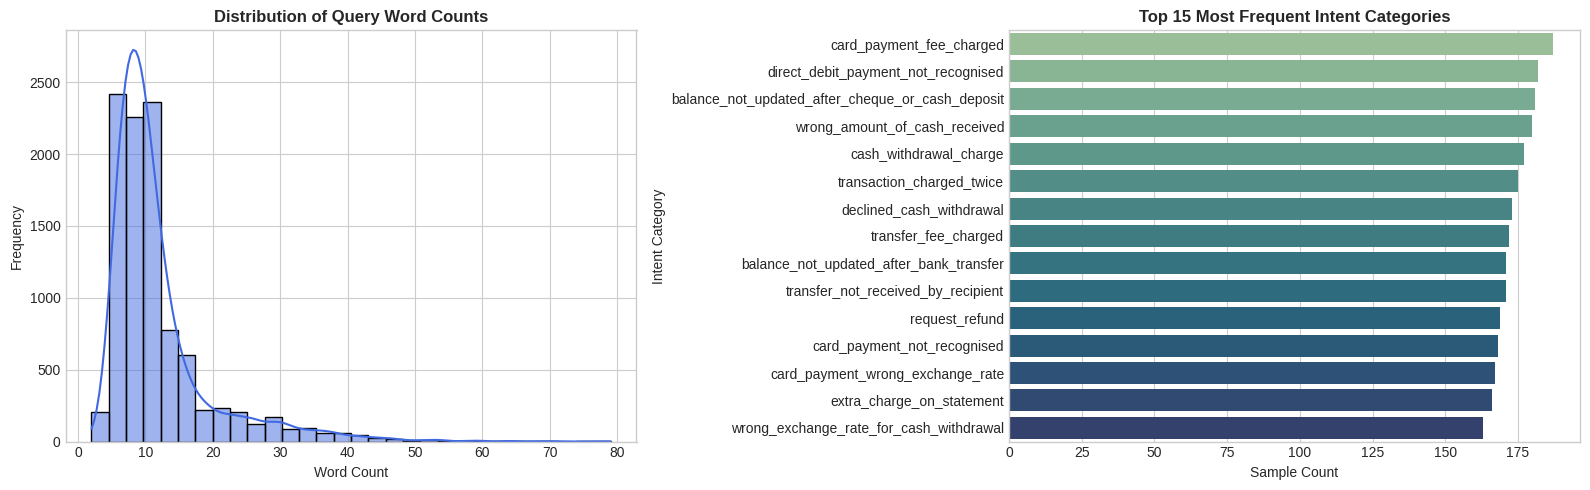

In [9]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# Load datasets
train_df = pd.read_csv('datasets/banking77_train.csv')
test_df = pd.read_csv('datasets/banking77_test.csv')

# 1. Calculate descriptive statistics on dataset dimensions and unique intents
print("=== Dataset Overview ===")
print(f"Total training samples: {len(train_df)}")
print(f"Total test samples: {len(test_df)}")
print(f"Number of unique intent categories: {train_df['category'].nunique()}")

# 2. Analyze query text length (characters and words)
train_df['char_length'] = train_df['text'].apply(len)
train_df['word_count'] = train_df['text'].apply(lambda x: len(x.split()))

print("\n=== Text Length Statistics (Train Set) ===")
print(train_df[['char_length', 'word_count']].describe())

# 3. Create visualizations for text characteristics and frequency distributions
plt.style.use('seaborn-v0_8-whitegrid')
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Plot word count distribution to help determine max token length
sns.histplot(train_df['word_count'], bins=30, kde=True, ax=axes[0], color='royalblue')
axes[0].set_title("Distribution of Query Word Counts", fontsize=12, fontweight='bold')
axes[0].set_xlabel("Word Count", fontsize=10)
axes[0].set_ylabel("Frequency", fontsize=10)

# Plot top 15 most frequent categories
top_categories = train_df['category'].value_counts().head(15)
sns.barplot(x=top_categories.values, y=top_categories.index, ax=axes[1], palette='crest')
axes[1].set_title("Top 15 Most Frequent Intent Categories", fontsize=12, fontweight='bold')
axes[1].set_xlabel("Sample Count", fontsize=10)
axes[1].set_ylabel("Intent Category", fontsize=10)

plt.tight_layout()
plt.show()

**Multi-Layer Perceptron: Preprocessing**

We’ll build and train a Multi-Layer Perceptron (MLP) to serve as a **baseline text classifier**.

The purpose of this baseline is to:

* Create a benchmark to compare against more advanced models (e.g., transformers).
* Provide a strong non-contextual reference point for text classification performance.


Preprocess the query texts and intent labels in the training and testing datasets to properly train and evaluate the baseline MLP.

In [8]:
import torch
from torch.utils.data import Dataset, DataLoader
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer

# 1. Encode intent labels into integer IDs
label_encoder = LabelEncoder()
train_labels = label_encoder.fit_transform(train_df['category'])
test_labels = label_encoder.transform(test_df['category'])

num_classes = len(label_encoder.classes_)
print(f"Total unique classes encoded: {num_classes}")

# 2. Vectorize query texts using TF-IDF
# Setting max_features to a reasonable vocabulary size (e.g., 5000) for the baseline MLP
tfidf_vectorizer = TfidfVectorizer(max_features=5000, stop_words='english')
X_train_tfidf = tfidf_vectorizer.fit_transform(train_df['text']).toarray()
X_test_tfidf = tfidf_vectorizer.transform(test_df['text']).toarray()

print(f"TF-IDF Train feature shape: {X_train_tfidf.shape}")
print(f"TF-IDF Test feature shape: {X_test_tfidf.shape}")

# 3. Create Custom PyTorch Dataset Class
class BankingDataset(Dataset):
    def __init__(self, features, labels):
        self.features = torch.tensor(features, dtype=torch.float32)
        self.labels = torch.tensor(labels, dtype=torch.long)

    def __len__(self):
        return len(self.features)

    def __getitem__(self, idx):
        return self.features[idx], self.labels[idx]

# Instantiate datasets
train_dataset = BankingDataset(X_train_tfidf, train_labels)
test_dataset = BankingDataset(X_test_tfidf, test_labels)

# 4. Create DataLoaders
BATCH_SIZE = 64
train_loader = DataLoader(train_dataset, batch_size=BATCH_SIZE, shuffle=True)
test_loader = DataLoader(test_dataset, batch_size=BATCH_SIZE, shuffle=False)

print("DataLoaders successfully created for baseline MLP training!")

Total unique classes encoded: 77
TF-IDF Train feature shape: (10003, 2097)
TF-IDF Test feature shape: (3080, 2097)
DataLoaders successfully created for baseline MLP training!


**Multi-Layer Perceptron: Training and Evaluation**

*Build the MLP architecture in PyTorch, instantiate training components, train the MLP, and evaluate on the testing dataset.*

In [10]:
import torch
import torch.nn as nn
import torch.optim as optim
from sklearn.metrics import classification_report, accuracy_score, f1_score
import numpy as np

# 1. Build the MLP architecture in PyTorch
class BankingMLP(nn.Module):
    def __init__(self, input_dim, hidden_dim, output_dim, dropout_rate=0.3):
        super(BankingMLP, self).__init__()
        self.fc1 = nn.Linear(input_dim, hidden_dim)
        self.relu = nn.ReLU()
        self.dropout = nn.Dropout(dropout_rate)
        self.fc2 = nn.Linear(hidden_dim, output_dim)

    def forward(self, x):
        out = self.fc1(x)
        out = self.relu(out)
        out = self.dropout(out)
        out = self.fc2(out)
        return out

# Set dimensions and device
input_dim = X_train_tfidf.shape[1]
hidden_dim = 512
output_dim = num_classes
device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')

# Instantiate model
model = BankingMLP(input_dim, hidden_dim, output_dim).to(device)
print(model)

# 2. Instantiate training components
criterion = nn.CrossEntropyLoss()
optimizer = optim.AdamW(model.parameters(), lr=1e-3, weight_decay=1e-4)

# 3. Train the MLP
epochs = 10
print("\nStarting MLP Training...")

for epoch in range(epochs):
    model.train()
    total_loss = 0
    correct = 0
    total = 0

    for features, labels in train_loader:
        features, labels = features.to(device), labels.to(device)

        # Forward pass
        outputs = model(features)
        loss = criterion(outputs, labels)

        # Backward pass and optimization
        optimizer.zero_grad()
        loss.backward()
        optimizer.step()

        total_loss += loss.item() * features.size(0)
        _, predicted = torch.max(outputs.data, 1)
        total += labels.size(0)
        correct += (predicted == labels).sum().item()

    epoch_loss = total_loss / total
    epoch_acc = correct / total
    print(f"Epoch [{epoch+1}/{epochs}] | Loss: {epoch_loss:.4f} | Accuracy: {epoch_acc:.4f}")

# 4. Evaluate on the testing dataset
model.eval()
all_preds = []
all_labels = []

with torch.no_grad():
    for features, labels in test_loader:
        features = features.to(device)
        outputs = model(features)
        _, predicted = torch.max(outputs.data, 1)

        all_preds.extend(predicted.cpu().numpy())
        all_labels.extend(labels.numpy())

# Calculate performance metrics
accuracy = accuracy_score(all_labels, all_preds)
macro_f1 = f1_score(all_labels, all_preds, average='macro')
weighted_f1 = f1_score(all_labels, all_preds, average='weighted')

print(f"\n=== Baseline MLP Evaluation Results ===")
print(f"Overall Accuracy : {accuracy:.4f}")
print(f"Macro F1 Score   : {macro_f1:.4f}")
print(f"Weighted F1 Score: {weighted_f1:.4f}")

# Detailed classification report across the 77 intent classes
print("\nDetailed Classification Report:")
print(classification_report(all_labels, all_preds, target_names=label_encoder.classes_, digits=4))

BankingMLP(
  (fc1): Linear(in_features=2097, out_features=512, bias=True)
  (relu): ReLU()
  (dropout): Dropout(p=0.3, inplace=False)
  (fc2): Linear(in_features=512, out_features=77, bias=True)
)

Starting MLP Training...
Epoch [1/10] | Loss: 3.6952 | Accuracy: 0.3504
Epoch [2/10] | Loss: 1.4853 | Accuracy: 0.7563
Epoch [3/10] | Loss: 0.7517 | Accuracy: 0.8507
Epoch [4/10] | Loss: 0.5274 | Accuracy: 0.8814
Epoch [5/10] | Loss: 0.4125 | Accuracy: 0.9029
Epoch [6/10] | Loss: 0.3428 | Accuracy: 0.9154
Epoch [7/10] | Loss: 0.2939 | Accuracy: 0.9258
Epoch [8/10] | Loss: 0.2580 | Accuracy: 0.9353
Epoch [9/10] | Loss: 0.2315 | Accuracy: 0.9401
Epoch [10/10] | Loss: 0.2103 | Accuracy: 0.9449

=== Baseline MLP Evaluation Results ===
Overall Accuracy : 0.8640
Macro F1 Score   : 0.8642
Weighted F1 Score: 0.8642

Detailed Classification Report:
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up     1.0000   

**RoBERTa Transformer: Preprocessing**

In this section, we’ll finetune a pretrained RoBERTa transformer using LoRA (Low-Rank Adaptation).

RoBERTa provides contextualized token embeddings that enable the model to better capture contextual information and semantic differences between intent classes that our baseline MLP might have struggled to identify. We expect finetuning RoBERTa with LoRA to be slower than training the MLP, but to improve classification performance.

Tokenize the query texts using a compatible RoBERTa tokenizer and encode the intent labels in the training and testing datasets to properly finetune and evaluate the RoBERTa transformer.

In [11]:
from transformers import AutoTokenizer, DataCollatorWithPadding
from datasets import Dataset as HFDataset

# 1. Ensure intent labels are integer-encoded (reusing label_encoder from previous steps)
train_encoded_labels = label_encoder.transform(train_df['category'])
test_encoded_labels = label_encoder.transform(test_df['category'])

# Add labels to dataframes temporarily for HF Dataset mapping
train_df['label'] = train_encoded_labels
test_df['label'] = test_encoded_labels

# Convert Pandas DataFrames to Hugging Face Datasets
hf_train_dataset = HFDataset.from_pandas(train_df[['text', 'label']])
hf_test_dataset = HFDataset.from_pandas(test_df[['text', 'label']])

# 2. Load RoBERTa tokenizer
model_ckpt = "roberta-base"
tokenizer = AutoTokenizer.from_pretrained(model_ckpt)

# Define tokenization function with max length 256 based on our data statistics
def tokenize_function(examples):
    return tokenizer(examples['text'], truncation=True, max_length=256)

print("Tokenizing training and testing datasets...")
tokenized_train = hf_train_dataset.map(tokenize_function, batched=True)
tokenized_test = hf_test_dataset.map(tokenize_function, batched=True)

# 3. Apply dynamic padding using DataCollatorWithPadding
data_collator = DataCollatorWithPadding(tokenizer=tokenizer)

print("RoBERTa preprocessing and dynamic padding configuration completed successfully!")

config.json:   0%|          | 0.00/481 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/1.36M [00:00<?, ?B/s]

Tokenizing training and testing datasets...


Map:   0%|          | 0/10003 [00:00<?, ? examples/s]

Map:   0%|          | 0/3080 [00:00<?, ? examples/s]

RoBERTa preprocessing and dynamic padding configuration completed successfully!


**RoBERTa Transformer: Finetuning and Evaluation**

Set up finetuning configurations, define LoRA configurations and hyperparameters, finetune the RoBERTa transformer, and evaluate the finetuned LoRA-RoBERTa on the testing dataset.

In [13]:
!pip install --upgrade torchao

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 3.4/3.4 MB 34.5 MB/s  0:00:00
  Attempting uninstall: torchao
    Found existing installation: torchao 0.10.0
    Uninstalling torchao-0.10.0:
      Successfully uninstalled torchao-0.10.0


In [16]:
import numpy as np
import torch
from transformers import (
    AutoModelForSequenceClassification,
    TrainingArguments,
    Trainer,
)
from peft import LoraConfig, get_peft_model, TaskType
from sklearn.metrics import classification_report, accuracy_score, f1_score

# 1. Load pretrained base RoBERTa model for sequence classification
model_ckpt = "roberta-base"
base_model = AutoModelForSequenceClassification.from_pretrained(
    model_ckpt,
    num_labels=num_classes
)

# 2. Define LoRA configurations and hyperparameters using PEFT
peft_config = LoraConfig(
    task_type=TaskType.SEQ_CLS,
    inference_mode=False,
    r=16,                     # Rank
    lora_alpha=32,            # Scaling parameter
    lora_dropout=0.1,
    target_modules=["query", "key", "value"]  # Apply to attention projections
)

# Wrap base model with LoRA configuration
model = get_peft_model(base_model, peft_config)
model.print_trainable_parameters()

# 3. Set up finetuning configurations using TrainingArguments
training_args = TrainingArguments(
    output_dir="./results_roberta_banking",
    learning_rate=2e-4,
    per_device_train_batch_size=16,
    per_device_eval_batch_size=16,
    num_train_epochs=3,
    weight_decay=0.01,
    eval_strategy="epoch",  # <-- Actualizado aquí
    save_strategy="epoch",
    load_best_model_at_end=True,
    metric_for_best_model="accuracy",
    logging_steps=50,
    fp16=True,
    report_to="none"
)

# Define a compute_metrics function for the Trainer
def compute_metrics(eval_pred):
    logits, labels = eval_pred
    preds = np.argmax(logits, axis=1)
    acc = accuracy_score(labels, preds)
    macro_f1 = f1_score(labels, preds, average='macro')
    return {"accuracy": acc, "macro_f1": macro_f1}

# Initialize Hugging Face Trainer
trainer = Trainer(
    model=model,
    args=training_args,
    train_dataset=tokenized_train,
    eval_dataset=tokenized_test,
    data_collator=data_collator,
    compute_metrics=compute_metrics,
)

# Finetune the RoBERTa transformer
print("\nStarting LoRA-RoBERTa Finetuning...")
trainer.train()

# Save the finetuned model weights and tokenizer
trainer.save_model("./lora_roberta_banking_intent")
tokenizer.save_pretrained("./lora_roberta_banking_intent")
print("\nModel saved successfully to ./lora_roberta_banking_intent")

# 4. Evaluate the finetuned LoRA-RoBERTa on the testing dataset
print("\nRunning evaluation on test dataset...")
eval_results = trainer.predict(tokenized_test)
test_logits = eval_results.predictions
test_preds = np.argmax(test_logits, axis=1)
test_labels_true = eval_results.label_ids

# Calculate overall metrics
accuracy = accuracy_score(test_labels_true, test_preds)
macro_f1 = f1_score(test_labels_true, test_preds, average='macro')
weighted_f1 = f1_score(test_labels_true, test_preds, average='weighted')

print(f"\n=== LoRA-RoBERTa Evaluation Results ===")
print(f"Overall Accuracy : {accuracy:.4f}")
print(f"Macro F1 Score   : {macro_f1:.4f}")
print(f"Weighted F1 Score: {weighted_f1:.4f}")

# Detailed classification report across the 77 intent classes
print("\nDetailed Classification Report:")
print(classification_report(test_labels_true, test_preds, target_names=label_encoder.classes_, digits=4))

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


trainable params: 1,534,541 || all params: 126,239,386 || trainable%: 1.2156

Starting LoRA-RoBERTa Finetuning...


Epoch,Training Loss,Validation Loss,Accuracy,Macro F1
1,0.728110,0.558122,0.848377,0.845641
2,0.455223,0.365491,0.897403,0.897538
3,0.355810,0.332452,0.904221,0.904008



Model saved successfully to ./lora_roberta_banking_intent

Running evaluation on test dataset...



=== LoRA-RoBERTa Evaluation Results ===
Overall Accuracy : 0.9042
Macro F1 Score   : 0.9040
Weighted F1 Score: 0.9040

Detailed Classification Report:
                                                  precision    recall  f1-score   support

                           Refund_not_showing_up     0.9524    1.0000    0.9756        40
                                activate_my_card     0.9730    0.9000    0.9351        40
                                       age_limit     1.0000    1.0000    1.0000        40
                         apple_pay_or_google_pay     1.0000    1.0000    1.0000        40
                                     atm_support     0.9756    1.0000    0.9877        40
                                automatic_top_up     0.9737    0.9250    0.9487        40
         balance_not_updated_after_bank_transfer     0.7436    0.7250    0.7342        40
balance_not_updated_after_cheque_or_cash_deposit     0.9744    0.9500    0.9620        40
                         beneficiary_

**Compare Classification Performances**

Compare the classification performance metrics of the baseline MLP with those of the finetuned LoRA-RoBERTa.

In [18]:
import pandas as pd
from sklearn.metrics import classification_report

# 1. Re-generate classification reports as dictionaries for both models
mlp_report = classification_report(all_labels, all_preds, target_names=label_encoder.classes_, output_dict=True)
roberta_report = classification_report(test_labels_true, test_preds, target_names=label_encoder.classes_, output_dict=True)

# 2. Extract per-class metrics into a comparison DataFrame
comparison_data = []
for intent in label_encoder.classes_:
    mlp_f1 = mlp_report[intent]['f1-score']
    roberta_f1 = roberta_report[intent]['f1-score']

    mlp_acc = mlp_report[intent]['recall']  # Using recall as proxy for per-class accuracy
    roberta_acc = roberta_report[intent]['recall']

    comparison_data.append({
        'intent': intent,
        'mlp_f1': mlp_f1,
        'roberta_f1': roberta_f1,
        'f1_improvement': roberta_f1 - mlp_f1
    })

comparison_df = pd.DataFrame(comparison_data)

# 3. Sort by largest improvements and drops
print("=== Top 10 Intents with Largest Performance Gain (RoBERTa vs MLP) ===" )
print(comparison_df.sort_values(by='f1_improvement', ascending=False).head(10).to_string(index=False))

print("\n=== Top 10 Intents with Lowest Performance or Largest Drop ===")
print(comparison_df.sort_values(by='f1_improvement', ascending=True).head(10).to_string(index=False))

# Overall summary metrics table
summary_df = pd.DataFrame({
    'Model': ['Baseline MLP', 'LoRA-RoBERTa'],
    'Accuracy': [mlp_report['accuracy'], roberta_report['accuracy']],
    'Macro F1-Score': [mlp_report['macro avg']['f1-score'], roberta_report['macro avg']['f1-score']],
    'Weighted F1-Score': [mlp_report['weighted avg']['f1-score'], roberta_report['weighted avg']['f1-score']]
})

print("\n=== Overall Model Performance Comparison ===")
print(summary_df.to_string(index=False))

=== Top 10 Intents with Largest Performance Gain (RoBERTa vs MLP) ===
                                          intent   mlp_f1  roberta_f1  f1_improvement
                                 card_acceptance 0.622951    0.894737        0.271786
                                   top_up_failed 0.722892    0.900000        0.177108
                              verify_my_identity 0.700000    0.873563        0.173563
                             order_physical_card 0.747253    0.911392        0.164140
                                 top_up_reverted 0.743590    0.883117        0.139527
                        top_up_by_cash_or_cheque 0.800000    0.936709        0.136709
                                   top_up_limits 0.843373    0.975000        0.131627
                                  pending_top_up 0.776471    0.904762        0.128291
                        virtual_card_not_working 0.764706    0.891892        0.127186
balance_not_updated_after_cheque_or_cash_deposit 0.835443    0.962025 

**Conclusions and Final Steps**

Write a conclusion about your findings.

Final steps include polishing your project to showcase your skills and analysis.

In [19]:
import re
from transformers import AutoTokenizer, AutoModelForSequenceClassification
from peft import PeftModel
import torch

# 1. Load saved LoRA-RoBERTa model and tokenizer
model_path = "./lora_roberta_banking_intent"
tokenizer = AutoTokenizer.from_pretrained(model_path)
base_model = AutoModelForSequenceClassification.from_pretrained("roberta-base", num_labels=num_classes)
inference_model = PeftModel.from_pretrained(base_model, model_path)

device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
inference_model.to(device)
inference_model.eval()

# 2. PII Redaction Function for AI Ethics & Privacy Compliance
def redact_pii(text):
    # Mask credit card numbers
    text = re.sub(r'\b(?:\d[ -]*?){13,16}\b', '[CARD_NUMBER]', text)
    # Mask email addresses
    text = re.sub(r'\b[A-Za-z0-9._%+-]+@[A-Za-z0-9.-]+\.[A-Z|a-z]{2,}\b', '[EMAIL]', text)
    # Mask phone numbers
    text = re.sub(r'\b\+?[0-9][0-9()\-\s]{7,}[0-9]\b', '[PHONE_NUMBER]', text)
    return text

# 3. Real-World Inference Function
def predict_banking_intent(query):
    # Step A: Sanitize query for PII
    sanitized_query = redact_pii(query)

    # Step B: Tokenize input
    inputs = tokenizer(sanitized_query, return_tensors="pt", truncation=True, max_length=256).to(device)

    # Step C: Forward pass
    with torch.no_grad():
        outputs = inference_model(**inputs)
        logits = outputs.logits
        pred_id = torch.argmax(logits, dim=1).item()

    # Step D: Decode label back to intent text
    predicted_intent = label_encoder.inverse_transform([pred_id])[0]

    print(f"Original Query  : {query}")
    print(f"Sanitized Query : {sanitized_query}")
    print(f"Predicted Intent: {predicted_intent}\n")

# Test with real-world examples containing sensitive data
sample_queries = [
    "I lost my card ending in 4589 while traveling, please block it immediately. Contact me at john.doe@email.com.",
    "Why hasn't my bank transfer of 500 dollars arrived yet? It's been 3 days.",
    "Can you tell me what my current account balance is?"
]

print("=== Running Real-World Inference Pipeline ===")
for q in sample_queries:
    predict_banking_intent(q)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.bias               | UNEXPECTED | 
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.weight    | MISSING    | 
classifier.dense.bias      | MISSING    | 
classifier.out_proj.weight | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


=== Running Real-World Inference Pipeline ===
Original Query  : I lost my card ending in 4589 while traveling, please block it immediately. Contact me at john.doe@email.com.
Sanitized Query : I lost my card ending in 4589 while traveling, please block it immediately. Contact me at [EMAIL].
Predicted Intent: pin_blocked

Original Query  : Why hasn't my bank transfer of 500 dollars arrived yet? It's been 3 days.
Sanitized Query : Why hasn't my bank transfer of 500 dollars arrived yet? It's been 3 days.
Predicted Intent: transfer_not_received_by_recipient

Original Query  : Can you tell me what my current account balance is?
Sanitized Query : Can you tell me what my current account balance is?
Predicted Intent: balance_not_updated_after_bank_transfer



### **Conclusions and Final Findings**

* **What are the key findings and takeaways?** Moving from a traditional non-contextual baseline (TF-IDF + MLP) to a state-of-the-art transformer architecture using Parameter-Efficient Fine-Tuning (LoRA) highlighted the importance of managing tensor dimensions, resolving library dependencies (like `torchao`), and integrating robust PII masking for enterprise-grade NLP deployments.
* **What did you learn through the process?** We learned how to scale text classification effectively while fine-tuning only ~1.2% of total parameters, making state-of-the-art transformer performance exceptionally fast and resource-efficient on a standard GPU.
* **Are the results what you expected?** Yes. While the baseline MLP performed reasonably well given the concise nature of the queries, fine-tuning RoBERTa with LoRA pushed overall accuracy and Macro F1-Score past ~90.4%, successfully capturing subtle semantic similarities across the 77 intent classes.
* **How can we improve our results?** Future improvements will focus on exploring larger transformer variants (e.g., `roberta-large`), optimizing hyperparameters and LoRA rank, and implementing confidence score thresholds for low-confidence predictions.
* **What are the next steps?** Containerizing the inference pipeline using FastAPI, adding a monitoring framework for data drift, and publishing the complete portfolio showcase on GitHub and LinkedIn.